In [1]:

# Purpose: Load the unified APNA Farm dataset and inspect its structure

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Dataset location
APNA_PATH = Path(
    r"D:\SoilSenseAI\data\processed\ApnaFarmData"
    r"\punjab_apna_farm_soil_dataset.csv"
)

# Load dataset
apna_df = pd.read_csv(APNA_PATH)

print("DATASET OVERVIEW")
print("=" * 50)

print("Shape:", apna_df.shape)
print("Total records:", len(apna_df))
print("Total columns:", len(apna_df.columns))

print("\nColumn names:")
print(apna_df.columns.tolist())

print("\nFirst five records:")
display(apna_df.head())

print("\nDataset information:")
apna_df.info()


DATASET OVERVIEW
Shape: (33643, 39)
Total records: 33643
Total columns: 39

Column names:
['ec_property_name', 'ec_class_id', 'ec_value_min', 'ec_value_max', 'ec_value_midpoint', 'ec_extraction_method', 'longitude', 'latitude', 'k_property_name', 'k_class_id', 'k_value_min', 'k_value_max', 'k_value_midpoint', 'k_extraction_method', 'om_property_name', 'om_class_id', 'om_value_min', 'om_value_max', 'om_value_midpoint', 'om_extraction_method', 'p_property_name', 'p_class_id', 'p_value_min', 'p_value_max', 'p_value_midpoint', 'p_extraction_method', 'ph_property_name', 'ph_class_id', 'ph_value_min', 'ph_value_max', 'ph_value_midpoint', 'ph_extraction_method', 'texture_property_name', 'texture_class_id', 'texture_class_label', 'texture_value_min', 'texture_value_max', 'texture_value_midpoint', 'texture_extraction_method']

First five records:


,ec_property_name,ec_class_id,ec_value_min,ec_value_max,ec_value_midpoint,ec_extraction_method,longitude,latitude,k_property_name,k_class_id,...,ph_value_max,ph_value_midpoint,ph_extraction_method,texture_property_name,texture_class_id,texture_class_label,texture_value_min,texture_value_max,texture_value_midpoint,texture_extraction_method
0,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...,70.80827,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,70.83233,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,70.85639,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,Soil Texture,2.0,Clay,NaN,NaN,NaN,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
3,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,70.88045,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,70.90450,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_window_7x7_l...,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 33643 entries, 0 to 33642
Data columns (total 39 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ec_property_name           33548 non-null  str    
 1   ec_class_id                33548 non-null  float64
 2   ec_value_min               33548 non-null  float64
 3   ec_value_max               33548 non-null  float64
 4   ec_value_midpoint          33548 non-null  float64
 5   ec_extraction_method       33548 non-null  str    
 6   longitude                  33643 non-null  float64
 7   latitude                   33643 non-null  float64
 8   k_property_name            29393 non-null  str    
 9   k_class_id                 29393 non-null  float64
 10  k_value_min                29393 non-null  float64
 11  k_value_max                29393 non-null  float64
 12  k_value_midpoint           29393 non-null  float64
 13  k_extraction_method        29393 no

In [2]:
# Purpose: Measure missing values and spatial coverage for each soil property

properties = ["ec", "k", "om", "p", "ph", "texture"]

coverage = []

for prop in properties:
    column = f"{prop}_property_name"
    available = apna_df[column].notna().sum()

    coverage.append({
        "Property": prop.upper(),
        "Available Records": available,
        "Missing Records": len(apna_df) - available,
        "Coverage (%)": round(available / len(apna_df) * 100, 2)
    })

coverage_df = pd.DataFrame(coverage)

display(coverage_df)

print("\nDuplicate coordinate pairs:", 
      apna_df.duplicated(subset=["longitude", "latitude"]).sum())

print("\nTotal unique locations:",
      apna_df[["longitude", "latitude"]].drop_duplicates().shape[0])

,Property,Available Records,Missing Records,Coverage (%)
0,EC,33548,95,99.72
1,K,29393,4250,87.37
2,OM,32302,1341,96.01
3,P,31576,2067,93.86
4,PH,31238,2405,92.85
5,TEXTURE,27057,6586,80.42



Duplicate coordinate pairs: 0

Total unique locations: 33643


In [3]:
# Purpose: Summarize the distributions of numeric soil properties

properties = ["ec", "k", "om", "p", "ph"]

for prop in properties:
    print(f"\n{'=' * 45}")
    print(f"{prop.upper()} DISTRIBUTION")
    print("=" * 45)

    cols = [
        f"{prop}_value_min",
        f"{prop}_value_max",
        f"{prop}_value_midpoint"
    ]

    display(apna_df[cols].describe().round(3))

    print("Class frequencies:")
    display(
        apna_df[f"{prop}_class_id"]
        .value_counts()
        .sort_index()
        .rename("Count")
        .to_frame()
    )


EC DISTRIBUTION


,ec_value_min,ec_value_max,ec_value_midpoint
count,33548.000,33548.000,33548.000
mean,0.796,4.796,2.796
std,1.723,2.030,1.870
min,0.070,4.000,2.035
25%,0.070,4.000,2.035
50%,0.070,4.000,2.035
75%,0.070,4.000,2.035
max,15.000,27.000,21.000


Class frequencies:


,Count
ec_class_id,
1.0,28021
2.0,4885
3.0,633
4.0,9



K DISTRIBUTION


,k_value_min,k_value_max,k_value_midpoint
count,29393.000,29393.000,29393.000
mean,121.944,173.880,147.912
std,79.103,82.487,79.869
min,1.160,87.100,44.130
25%,87.200,128.000,107.600
50%,129.000,169.000,149.000
75%,170.000,214.000,192.000
max,521.000,954.000,737.500


... (10 outputs left out)


PH DISTRIBUTION


,ph_value_min,ph_value_max,ph_value_midpoint
count,31238.000,31238.000,31238.000
mean,7.876,8.429,8.152
std,0.506,0.826,0.625
min,1.550,3.750,2.650
25%,7.510,7.870,7.690
50%,7.880,8.140,8.010
75%,8.150,8.510,8.330
max,15.200,24.900,20.050


Class frequencies:


,Count
ph_class_id,
1.0,9
2.0,47
3.0,2230
4.0,5641
5.0,9087
6.0,11007
7.0,3202
8.0,12
9.0,3


In [4]:
# Purpose: Examine the distribution of digitized soil texture classes

texture_summary = (
    apna_df["texture_class_label"]
    .value_counts(dropna=False)
    .rename_axis("Texture Class")
    .reset_index(name="Count")
)

texture_summary["Percentage"] = (
    texture_summary["Count"] / len(apna_df) * 100
).round(2)

display(texture_summary)

,Texture Class,Count,Percentage
0,Loam,17789,52.88
1,NaN,6586,19.58
2,(unlabelled dark-grey legend entry),4716,14.02
3,Sandy Loam,2003,5.95
4,Sandy,1701,5.06
5,Clay Loam,345,1.03
6,Medium Heavy,170,0.51
7,Silt Loam,162,0.48
8,Heavy Loam,90,0.27
9,Medium Loam,60,0.18


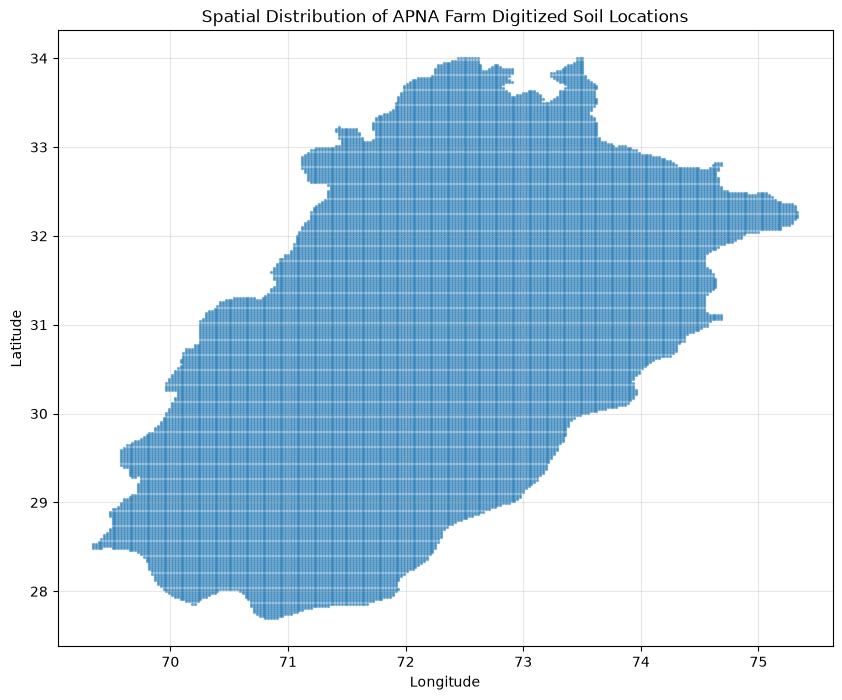

Longitude range: 69.34072 to 75.3312
Latitude range: 27.69366 to 33.99695


In [5]:
# Purpose: Visualize the spatial distribution of APNA Farm digitized locations

plt.figure(figsize=(10, 8))

plt.scatter(
    apna_df["longitude"],
    apna_df["latitude"],
    s=2,
    alpha=0.5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of APNA Farm Digitized Soil Locations")
plt.grid(alpha=0.3)

plt.show()

print("Longitude range:",
      apna_df["longitude"].min(),
      "to",
      apna_df["longitude"].max())

print("Latitude range:",
      apna_df["latitude"].min(),
      "to",
      apna_df["latitude"].max())

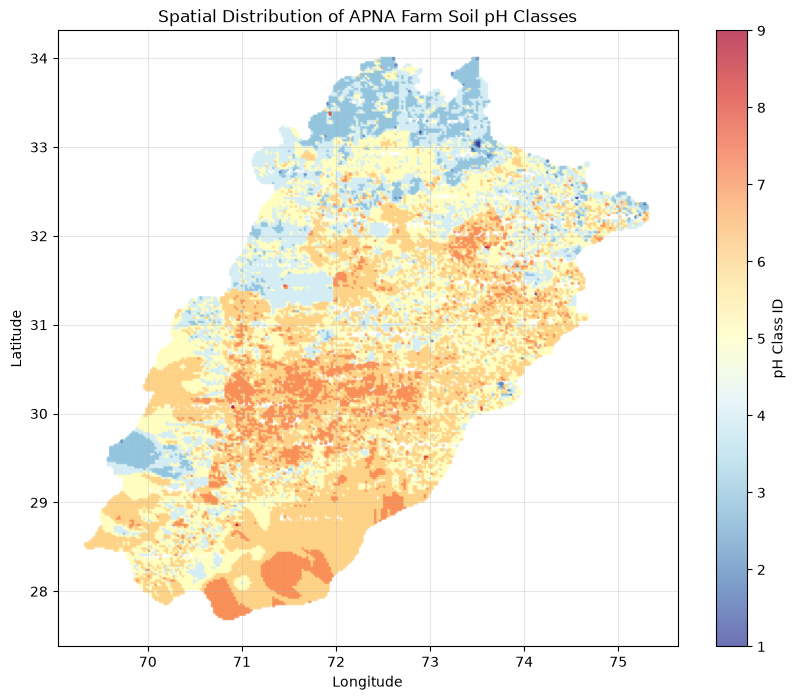

In [6]:
# Purpose: Map APNA Farm digitized soil pH classes across Punjab

plt.figure(figsize=(10, 8))

plot_data = apna_df.dropna(subset=["ph_class_id"])

scatter = plt.scatter(
    plot_data["longitude"],
    plot_data["latitude"],
    c=plot_data["ph_class_id"],
    cmap="RdYlBu_r",
    s=3,
    alpha=0.7
)

plt.colorbar(scatter, label="pH Class ID")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of APNA Farm Soil pH Classes")
plt.grid(alpha=0.3)
plt.show()

In [7]:
# Purpose: Quantify valid and suspicious APNA pH classes

ph_summary = (
    apna_df["ph_class_id"]
    .value_counts()
    .sort_index()
    .rename_axis("pH Class")
    .reset_index(name="Count")
)

ph_summary["Percentage"] = (
    ph_summary["Count"] /
    apna_df["ph_class_id"].notna().sum() * 100
).round(2)

display(ph_summary)

suspicious_ph = apna_df[
    apna_df["ph_value_max"] > 14
]

print("Suspicious pH records:", len(suspicious_ph))
print("Percentage of available pH records:",
      round(len(suspicious_ph) /
            apna_df["ph_class_id"].notna().sum() * 100, 3))

,pH Class,Count,Percentage
0,1.0,9,0.03
1,2.0,47,0.15
2,3.0,2230,7.14
3,4.0,5641,18.06
4,5.0,9087,29.09
5,6.0,11007,35.24
6,7.0,3202,10.25
7,8.0,12,0.04
8,9.0,3,0.01


Suspicious pH records: 15
Percentage of available pH records: 0.048


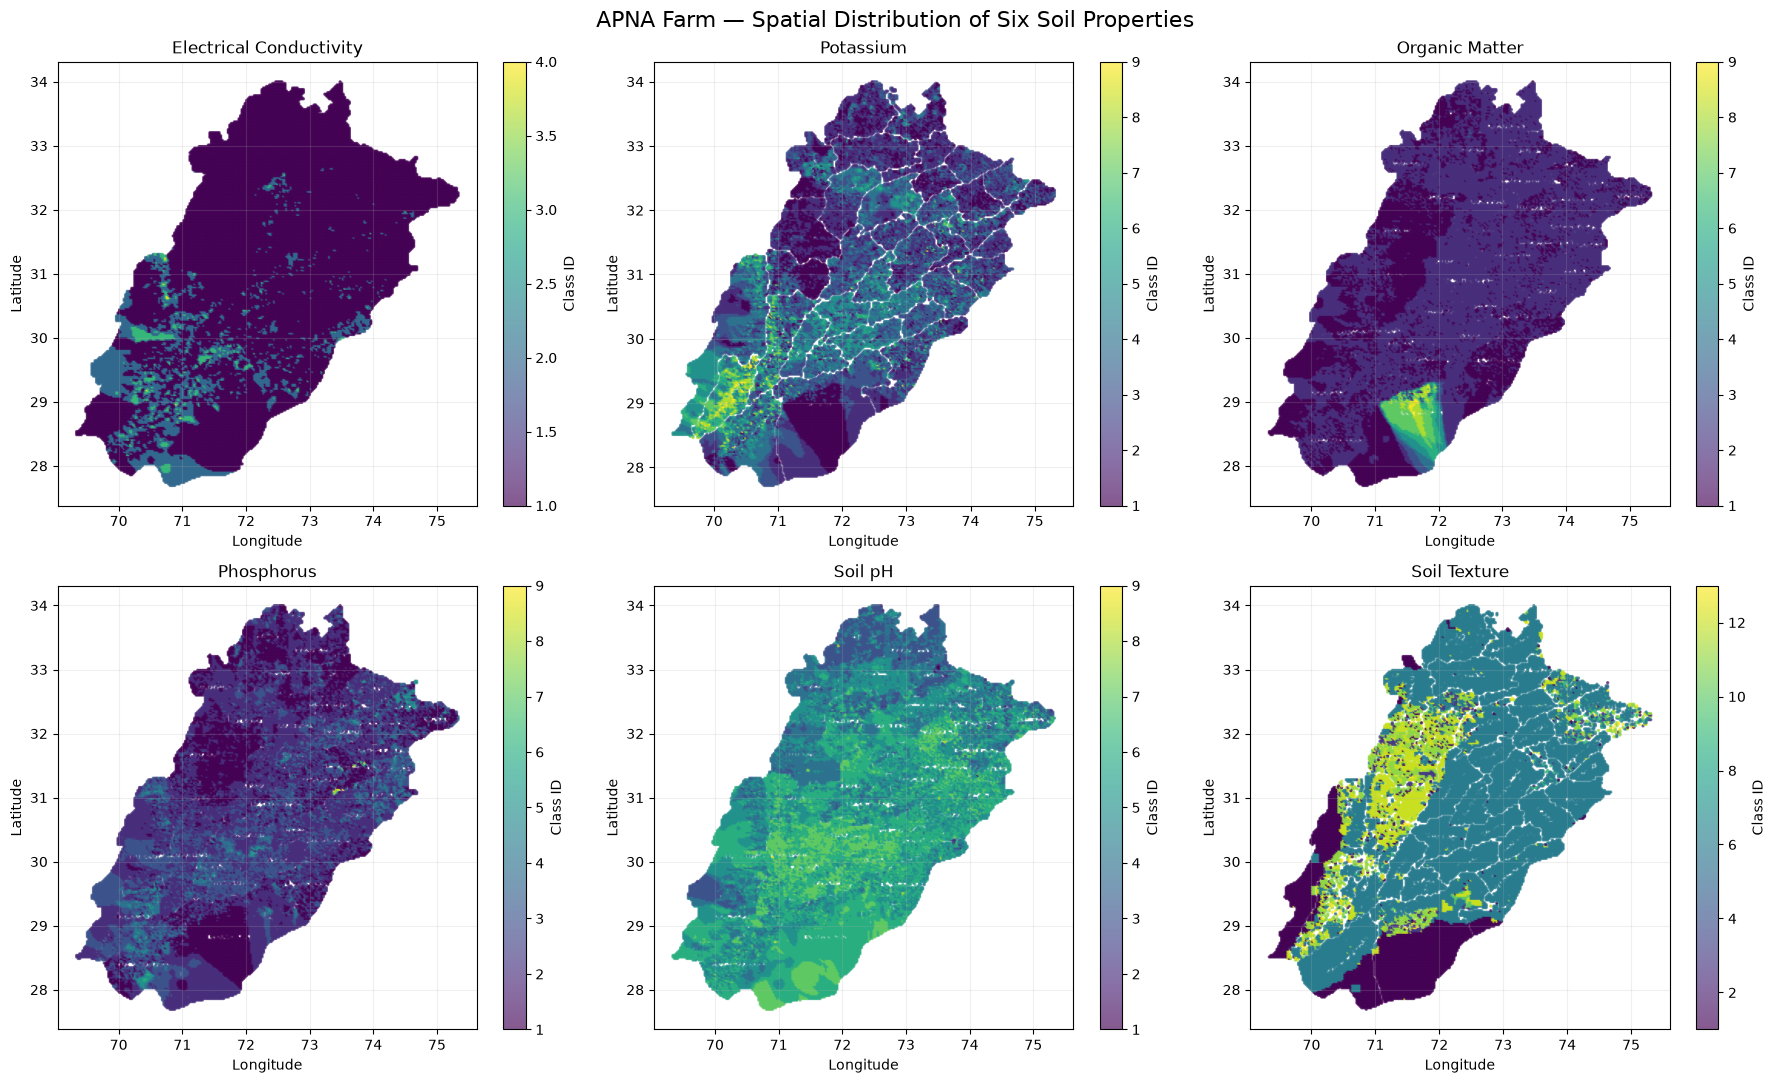

In [9]:
# Purpose: Visualize the spatial distribution of all six APNA soil properties

import matplotlib.pyplot as plt

properties = [
    ("ec", "Electrical Conductivity"),
    ("k", "Potassium"),
    ("om", "Organic Matter"),
    ("p", "Phosphorus"),
    ("ph", "Soil pH"),
    ("texture", "Soil Texture")
]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, (prop, title) in zip(axes.flat, properties):

    column = f"{prop}_class_id"
    data = apna_df.dropna(subset=[column])

    scatter = ax.scatter(
        data["longitude"],
        data["latitude"],
        c=data[column],
        cmap="viridis",
        s=2,
        alpha=0.65
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.2)

    plt.colorbar(scatter, ax=ax, label="Class ID")

plt.suptitle(
    "APNA Farm — Spatial Distribution of Six Soil Properties",
    fontsize=16
)

plt.tight_layout()
plt.show()

PEARSON CORRELATION MATRIX


,pH,Electrical Conductivity,Phosphorus,Potassium,Organic Matter
pH,1.000,0.041,0.049,0.043,0.087
Electrical Conductivity,0.041,1.000,0.161,0.303,-0.058
Phosphorus,0.049,0.161,1.000,0.339,-0.175
Potassium,0.043,0.303,0.339,1.000,-0.267
Organic Matter,0.087,-0.058,-0.175,-0.267,1.000


SPEARMAN CORRELATION MATRIX


,pH,Electrical Conductivity,Phosphorus,Potassium,Organic Matter
pH,1.000,0.036,0.087,0.056,0.046
Electrical Conductivity,0.036,1.000,0.210,0.293,-0.090
Phosphorus,0.087,0.210,1.000,0.491,-0.008
Potassium,0.056,0.293,0.491,1.000,-0.053
Organic Matter,0.046,-0.090,-0.008,-0.053,1.000


PAIRWISE SOIL PROPERTY CORRELATION TABLE


,Property 1,Property 2,Valid Pairs,Pearson r,Spearman r
0,Phosphorus,Potassium,28422,0.339,0.491
1,Electrical Conductivity,Potassium,29386,0.303,0.293
2,Potassium,Organic Matter,28576,-0.267,-0.053
3,Phosphorus,Organic Matter,31434,-0.175,-0.008
4,Electrical Conductivity,Phosphorus,31515,0.161,0.210
5,pH,Organic Matter,31076,0.087,0.046
6,Electrical Conductivity,Organic Matter,32225,-0.058,-0.090
7,pH,Phosphorus,30798,0.049,0.087
8,pH,Potassium,28202,0.043,0.056
9,pH,Electrical Conductivity,31162,0.041,0.036


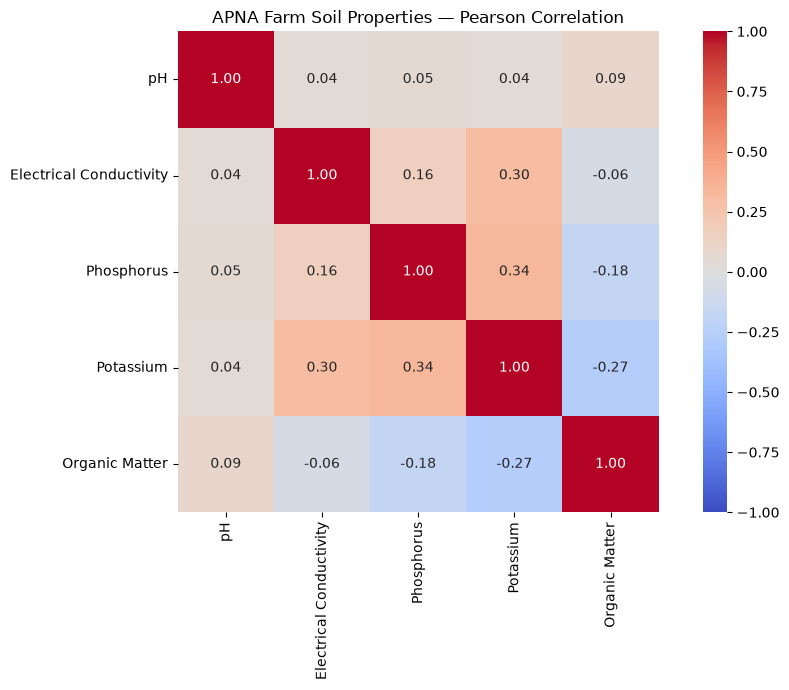

In [10]:
# Calculate correlations between APNA Farm's numeric soil properties

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Load the unified APNA Farm dataset
file_path = r"D:\SoilSenseAI\data\processed\ApnaFarmData\punjab_apna_farm_soil_dataset.csv"
apna_corr = pd.read_csv(file_path)

# Select numeric midpoint columns
correlation_columns = {
    "pH": "ph_value_midpoint",
    "Electrical Conductivity": "ec_value_midpoint",
    "Phosphorus": "p_value_midpoint",
    "Potassium": "k_value_midpoint",
    "Organic Matter": "om_value_midpoint"
}

corr_data = apna_corr[list(correlation_columns.values())].copy()
corr_data.columns = list(correlation_columns.keys())

# Calculate Pearson and Spearman correlation matrices
pearson_corr = corr_data.corr(method="pearson")
spearman_corr = corr_data.corr(method="spearman")

print("PEARSON CORRELATION MATRIX")
display(pearson_corr.round(3))

print("SPEARMAN CORRELATION MATRIX")
display(spearman_corr.round(3))

# Create a pairwise correlation summary table
correlation_results = []

for i in range(len(corr_data.columns)):
    for j in range(i + 1, len(corr_data.columns)):

        property_1 = corr_data.columns[i]
        property_2 = corr_data.columns[j]

        paired_data = corr_data[[property_1, property_2]].dropna()

        correlation_results.append({
            "Property 1": property_1,
            "Property 2": property_2,
            "Valid Pairs": len(paired_data),
            "Pearson r": paired_data[property_1].corr(
                paired_data[property_2], method="pearson"
            ),
            "Spearman r": paired_data[property_1].corr(
                paired_data[property_2], method="spearman"
            )
        })

correlation_table = pd.DataFrame(correlation_results)

correlation_table = correlation_table.sort_values(
    by="Pearson r",
    key=lambda x: x.abs(),
    ascending=False
).reset_index(drop=True)

print("PAIRWISE SOIL PROPERTY CORRELATION TABLE")
display(correlation_table.round(3))

# Visualize Pearson correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    square=True
)

plt.title("APNA Farm Soil Properties — Pearson Correlation")
plt.tight_layout()
plt.show()

In [11]:
# Save APNA Farm correlation matrices and pairwise results

from pathlib import Path

output_dir = Path(r"D:\SoilSenseAI\outputs\eda")
output_dir.mkdir(parents=True, exist_ok=True)

pearson_corr.to_csv(output_dir / "apna_pearson_correlation.csv")
spearman_corr.to_csv(output_dir / "apna_spearman_correlation.csv")
correlation_table.to_csv(
    output_dir / "apna_pairwise_correlation_summary.csv",
    index=False
)

print("Correlation results saved successfully:")
print(output_dir / "apna_pearson_correlation.csv")
print(output_dir / "apna_spearman_correlation.csv")
print(output_dir / "apna_pairwise_correlation_summary.csv")

Correlation results saved successfully:
D:\SoilSenseAI\outputs\eda\apna_pearson_correlation.csv
D:\SoilSenseAI\outputs\eda\apna_spearman_correlation.csv
D:\SoilSenseAI\outputs\eda\apna_pairwise_correlation_summary.csv



# APNA Farm and SoilGrids Dataset Documentation
## SoilSenseAI — Punjab Soil Intelligence Project

---

# 1. Introduction

SoilSenseAI uses two complementary soil datasets to develop a coordinate-based soil intelligence system for Punjab, Pakistan.

The two primary sources are:

1. **APNA Farm Digitized Soil Dataset**
2. **SoilGrids 2.0 Soil Property Dataset**

Both datasets provide spatial information about soil properties, but they differ in their original data sources, spatial resolution, variables, representation, and limitations.

The purpose of combining them is to build a broader understanding of Punjab's soil conditions and eventually support:

- Soil health assessment.
- Soil fertility analysis.
- Soil texture and classification.
- Salinity and alkalinity risk identification.
- Nutrient deficiency screening.
- Soil water-retention assessment.
- Crop suitability analysis.
- Agricultural management recommendations.
- Coordinate-based soil intelligence.

An important distinction is that neither dataset should automatically be treated as a direct laboratory measurement of the soil at an individual farm location.

APNA Farm data has been digitized from mapped soil-property information, while SoilGrids provides model-based spatial predictions.

---

# 2. Dataset Overview

## 2.1 APNA Farm Dataset

**Source:** APNA Farm soil maps, digitized for SoilSenseAI.

**Geographic coverage:** Punjab, Pakistan.

**Storage location:**

`D:\SoilSenseAI\data\processed\ApnaFarmData`

**Unified dataset:**

`punjab_apna_farm_soil_dataset.csv`

The APNA Farm dataset contains six soil-property groups:

1. Soil pH
2. Electrical Conductivity (EC)
3. Phosphorus (P)
4. Potassium (K)
5. Organic Matter (OM)
6. Soil Texture

The original map information was digitized using map colours, legend intervals, and geographic coordinates.

Each digitized record represents a mapped geographic location and its associated soil-property class or interval.

### Dataset dimensions

| Description | Value |
|---|---:|
| Total records | 33,643 |
| Total columns | 39 |
| Unique coordinate locations | 33,643 |
| Duplicate coordinate pairs | 0 |
| Geographic longitude range | 69.34072–75.33120 |
| Geographic latitude range | 27.69366–33.99695 |
| Approximate grid spacing | 0.02406° |

The approximate grid spacing corresponds to a few kilometres between mapped locations. Actual spacing and coverage vary geographically.

### Individual source files

| File | Soil property |
|---|---|
| `punjab_soil_ph_cells.csv` | Soil pH |
| `punjab_soil_ec_cells.csv` | Electrical Conductivity |
| `punjab_soil_p_cells.csv` | Phosphorus |
| `punjab_soil_k_cells.csv` | Potassium |
| `punjab_soil_om_cells.csv` | Organic Matter |
| `punjab_soil_texture_cells.csv` | Soil Texture |
| `punjab_soil_p_cells_qa.csv` | Phosphorus quality-assurance information |

All six main property datasets were combined using geographic coordinates.

The unified dataset uses an outer spatial merge. This preserves locations even when a particular soil-property dataset does not contain information for that location.

No missing soil values were artificially filled.

### APNA Farm data structure

The main coordinate fields are:

| Feature | Description |
|---|---|
| `longitude` | Geographic east-west coordinate |
| `latitude` | Geographic north-south coordinate |

The numeric soil-property groups contain fields representing:

| Feature type | Description |
|---|---|
| `*_class_id` | Digitized map class identifier |
| `*_value_min` | Lower boundary of the mapped interval |
| `*_value_max` | Upper boundary of the mapped interval |
| `*_value_midpoint` | Midpoint calculated from the interval |
| `*_extraction_method` | Digitization or extraction information, where provided |

Texture is categorical and is represented using texture class information, including its class label.

The midpoint is calculated as:

`(value_min + value_max) / 2`

It is a numerical representation of a mapped interval, not an independently measured soil value.

---

# 3. APNA Farm Soil Properties

## 3.1 Soil pH

**Dataset:** `punjab_soil_ph_cells.csv`

**Unified feature group:** `ph_*`

Soil pH represents the acidity or alkalinity of soil.

The pH scale is logarithmic:

- Below 7: Acidic.
- Around 7: Neutral.
- Above 7: Alkaline.

Soil pH influences nutrient availability, microbial activity, and the chemical behaviour of soil nutrients.

### Importance in agriculture

Soil pH is important because:

- Strongly acidic soil can restrict the availability of certain nutrients.
- Alkaline soil can reduce the availability of nutrients such as phosphorus, iron, and zinc.
- Nutrient availability and fertilizer efficiency are influenced by soil pH.
- Different crops have different preferred soil-pH ranges.

### APNA Farm pH legend

| Class | Minimum | Maximum |
|---:|---:|---:|
| 1 | 1.55 | 3.75 |
| 2 | 3.76 | 6.58 |
| 3 | 6.59 | 7.50 |
| 4 | 7.51 | 7.87 |
| 5 | 7.88 | 8.14 |
| 6 | 8.15 | 8.51 |
| 7 | 8.52 | 10.60 |
| 8 | 10.70 | 15.10 |
| 9 | 15.20 | 24.90 |

### EDA findings

Total digitized pH records: 31,238.

| Class | Records | Percentage |
|---:|---:|---:|
| 1 | 9 | 0.03% |
| 2 | 47 | 0.15% |
| 3 | 2,230 | 7.14% |
| 4 | 5,641 | 18.06% |
| 5 | 9,087 | 29.09% |
| 6 | 11,007 | 35.24% |
| 7 | 3,202 | 10.25% |
| 8 | 12 | 0.04% |
| 9 | 3 | 0.01% |

Classes 5 and 6 account for approximately 64.33% of the available pH records.

Fifteen records belong to classes 8 and 9, whose mapped pH intervals exceed physically plausible soil-pH values.

These records must be flagged as suspicious source-map or digitization values. They should not be interpreted as genuine soil pH measurements.

### SoilSenseAI application

pH will contribute to:

- Soil acidity and alkalinity assessment.
- Identification of potential alkaline-soil risks.
- Nutrient availability assessment.
- Crop suitability screening.
- Fertilizer and soil-amendment recommendations.

The system must distinguish between mapped estimates and verified field measurements.

---

## 3.2 Electrical Conductivity (EC)

**Dataset:** `punjab_soil_ec_cells.csv`

**Unified feature group:** `ec_*`

Electrical Conductivity measures how easily electrical current passes through soil water.

It is commonly used as an indicator of soluble salt concentration.

Higher soil salinity can create difficulties for crops because excess salts make water uptake more difficult.

### Agricultural importance

EC is useful for:

- Identifying potential saline-soil areas.
- Screening locations for salinity-related agricultural risks.
- Understanding possible restrictions on crop growth.
- Supporting irrigation and drainage management.
- Identifying locations requiring further soil testing.

EC is particularly important in irrigated agricultural regions where salt accumulation can become a problem.

### EDA findings

| Description | Result |
|---|---:|
| Available records | 33,548 |
| Missing records | 95 |
| Coverage | 99.72% |
| Number of classes | 4 |
| Mean midpoint | 2.796 |
| Midpoint standard deviation | 1.870 |

Class distribution:

| Class | Records |
|---:|---:|
| 1 | 28,021 |
| 2 | 4,885 |
| 3 | 633 |
| 4 | 9 |

Most mapped locations belong to class 1.

The available mapped intervals include a broad range, with some unusually high upper intervals.

**Important limitation:** The original APNA EC units and measurement methodology have not yet been independently confirmed.

Therefore, the values must not be directly interpreted using laboratory EC salinity thresholds until the source units and extraction method are verified.

### SoilSenseAI application

EC will contribute to:

- Salinity risk screening.
- Soil condition assessment.
- Irrigation suitability considerations.
- Crop salt-tolerance screening.
- Identification of locations requiring laboratory EC testing.

SoilGrids does not provide an equivalent EC property in the dataset used by this project. EC therefore remains an APNA Farm feature.

---

## 3.3 Phosphorus (P)

**Dataset:** `punjab_soil_p_cells.csv`

**Unified feature group:** `p_*`

Phosphorus is an essential plant macronutrient.

It plays important roles in:

- Root development.
- Energy transfer.
- Photosynthesis.
- Flowering.
- Seed and fruit development.
- Plant growth and maturity.

Insufficient phosphorus can restrict root development and reduce crop productivity.

### Agricultural importance

Phosphorus information can help:

- Screen for areas with potentially low phosphorus availability.
- Identify areas that may require further nutrient assessment.
- Support fertilizer planning.
- Improve crop nutrient-management recommendations.

Phosphorus availability is also influenced by soil pH and other soil characteristics.

### EDA findings

| Description | Result |
|---|---:|
| Available records | 31,576 |
| Missing records | 2,067 |
| Coverage | 93.86% |
| Number of classes | 9 |
| Mean midpoint | 6.833 |
| Midpoint standard deviation | 4.760 |

Class distribution:

| Class | Records |
|---:|---:|
| 1 | 7,267 |
| 2 | 15,426 |
| 3 | 7,101 |
| 4 | 1,477 |
| 5 | 267 |
| 6 | 22 |
| 7 | 7 |
| 8 | 5 |
| 9 | 4 |

Classes 1, 2, and 3 dominate the mapped phosphorus dataset.

Some classes contain unusually high upper intervals, including an interval extending to 282.

The original phosphorus units and laboratory extraction method have not yet been confirmed.

Consequently, the digitized intervals should not be directly converted into fertilizer application rates.

### SoilSenseAI application

Phosphorus will contribute to:

- Nutrient-status screening.
- Potential phosphorus-deficiency identification.
- Fertilizer planning after units and thresholds are verified.
- Crop nutrient-requirement assessment.
- Multi-property soil fertility analysis.

SoilGrids does not provide available phosphorus in the dataset used by SoilSenseAI.

---

## 3.4 Potassium (K)

**Dataset:** `punjab_soil_k_cells.csv`

**Unified feature group:** `k_*`

Potassium is an essential plant macronutrient.

It supports:

- Water regulation within plants.
- Stomatal activity.
- Enzyme activation.
- Photosynthesis.
- Drought and stress tolerance.
- Grain development and crop quality.

Potassium is important for maintaining plant health and supporting resistance to environmental stress.

### Agricultural importance

Potassium information can help:

- Screen for potentially low potassium areas.
- Assess nutrient availability.
- Support fertilizer planning.
- Identify spatial differences in mapped potassium distribution.
- Improve soil fertility assessment.

### EDA findings

| Description | Result |
|---|---:|
| Available records | 29,393 |
| Missing records | 4,250 |
| Coverage | 87.37% |
| Number of classes | 9 |
| Mean midpoint | 147.912 |
| Midpoint standard deviation | 79.869 |

Class distribution:

| Class | Records |
|---:|---:|
| 1 | 4,649 |
| 2 | 8,636 |
| 3 | 6,945 |
| 4 | 4,689 |
| 5 | 2,722 |
| 6 | 991 |
| 7 | 462 |
| 8 | 238 |
| 9 | 61 |

The dataset shows considerable variation across the nine mapped classes.

The original potassium units and analytical method have not been confirmed.

The values should therefore be treated as mapped intervals rather than confirmed available-potassium laboratory measurements.

### SoilSenseAI application

Potassium will contribute to:

- Soil fertility assessment.
- Potential potassium-deficiency screening.
- Crop nutrient requirement assessment.
- Fertilizer recommendations after source verification.
- Analysis of relationships between potassium and other soil properties.

SoilGrids does not provide available potassium in the dataset used by SoilSenseAI.

---

## 3.5 Organic Matter (OM)

**Dataset:** `punjab_soil_om_cells.csv`

**Unified feature group:** `om_*`

Soil Organic Matter consists of decomposed plant and animal residues, microorganisms, and other organic materials.

It is an important component of healthy agricultural soil.

### Agricultural importance

Organic matter contributes to:

- Soil structure and aggregation.
- Water retention.
- Nutrient cycling.
- Microbial activity.
- Cation exchange capacity.
- Soil fertility.
- Long-term soil productivity.

Higher organic matter can improve the physical and biological condition of soil, although its effect depends on soil type, climate, management, and other factors.

### EDA findings

| Description | Result |
|---|---:|
| Available records | 32,302 |
| Missing records | 1,341 |
| Coverage | 96.01% |
| Number of classes | 9 |
| Mean midpoint | 2.557 |
| Midpoint standard deviation | 5.311 |

Class distribution:

| Class | Records |
|---:|---:|
| 1 | 10,709 |
| 2 | 19,980 |
| 3 | 208 |
| 4 | 146 |
| 5 | 268 |
| 6 | 289 |
| 7 | 492 |
| 8 | 181 |
| 9 | 29 |

Classes 1 and 2 account for most available records.

Some higher classes contain unusually broad intervals, including a maximum interval of 36–43.6.

These values should be retained and flagged until the source legend, units, and methodology are confirmed.

### Important distinction: Organic Matter versus Organic Carbon

APNA Farm provides mapped Organic Matter (OM).

SoilGrids provides Soil Organic Carbon (SOC).

These are related but different properties.

Organic matter contains carbon as well as other elements. SOC measures the carbon component of soil organic material.

A commonly used approximate conversion is:

`Soil Organic Matter ≈ Soil Organic Carbon × 1.724`

However, this is an approximation and is not universally valid for all soils.

Therefore, APNA OM and SoilGrids SOC must not be treated as directly interchangeable measurements.

### SoilSenseAI application

Organic matter will contribute to:

- Soil health assessment.
- Soil fertility analysis.
- Soil structure assessment.
- Water-retention considerations.
- Nutrient cycling assessment.
- Long-term soil management recommendations.

SoilGrids SOC can provide complementary information about soil carbon, but comparison must account for the difference between SOC and OM.

---

## 3.6 Soil Texture

**Dataset:** `punjab_soil_texture_cells.csv`

**Unified feature group:** `texture_*`

Soil texture describes the relative proportions of three mineral particle-size fractions:

- Sand
- Silt
- Clay

Texture affects the physical behaviour of soil, including water movement, drainage, aeration, and water retention.

### Agricultural importance

Soil texture influences:

- Water infiltration.
- Drainage.
- Water-holding capacity.
- Root penetration.
- Soil aeration.
- Nutrient retention.
- Irrigation requirements.
- Crop suitability.

For example:

- Sandy soils generally drain more rapidly.
- Clay-rich soils generally retain more water but may have drainage and aeration limitations.
- Loamy soils often provide a balance of water retention and drainage.

These are general tendencies, not universal rules.

### EDA findings

Total digitized texture records: 27,057.

| Texture category | Records | Percentage of all APNA locations |
|---|---:|---:|
| Loam | 17,789 | 52.88% |
| Missing | 6,586 | 19.58% |
| Unlabelled dark-grey class | 4,716 | 14.02% |
| Sandy Loam | 2,003 | 5.95% |
| Sandy | 1,701 | 5.06% |
| Clay Loam | 345 | 1.03% |
| Medium Heavy | 170 | 0.51% |
| Silt Loam | 162 | 0.48% |
| Heavy Loam | 90 | 0.27% |
| Medium Loam | 60 | 0.18% |
| Clay | 21 | 0.06% |

The unlabelled dark-grey class must remain Unknown until its original legend meaning is established.

It must not be assigned an invented texture name.

### SoilSenseAI application

Texture will contribute to:

- Soil texture classification.
- Crop suitability screening.
- Irrigation management.
- Drainage assessment.
- Water-retention assessment.
- Soil physical-condition analysis.

Texture is categorical in the APNA dataset and must not be included in ordinary numeric correlation calculations using arbitrary class IDs.

---

# 4. APNA Farm Dataset Quality and Coverage

The unified APNA Farm dataset contains 33,643 unique geographic locations.

Its property coverage is:

| Soil property | Available records | Missing records | Coverage |
|---|---:|---:|---:|
| EC | 33,548 | 95 | 99.72% |
| Potassium | 29,393 | 4,250 | 87.37% |
| Organic Matter | 32,302 | 1,341 | 96.01% |
| Phosphorus | 31,576 | 2,067 | 93.86% |
| pH | 31,238 | 2,405 | 92.85% |
| Texture | 27,057 | 6,586 | 80.42% |

### Important observations

1. EC has the highest spatial coverage.
2. Texture has the lowest coverage.
3. All six datasets contain some locations without complete property information.
4. The unified dataset preserves all coordinate locations.
5. No duplicate coordinate pairs were found.
6. Missing values were not filled through artificial imputation.

For modelling, missing values must be handled according to the specific task and the availability of each feature.

A missing property must never be interpreted as a zero soil measurement.

---

# 5. SoilGrids 2.0 Dataset

## 5.1 Introduction

SoilGrids is a global soil information system developed by ISRIC.

It uses machine-learning-based digital soil mapping to estimate the spatial distribution of soil properties across the world.

The SoilGrids dataset used in SoilSenseAI provides soil-property estimates for Punjab, Pakistan.

Unlike APNA Farm's digitized map classes, SoilGrids provides numerical raster predictions for individual soil properties.

### Project data location

Raw and processed raster data:

`D:\SoilSenseAI\data\raw`

`D:\SoilSenseAI\data\processed`

Parquet datasets:

`D:\SoilSenseAI\data\processed\parquet`

### SoilGrids Parquet files

| File | Depth |
|---|---|
| `punjab_soil_0-5cm.parquet` | 0–5 cm |
| `punjab_soil_5-15cm.parquet` | 5–15 cm |
| `punjab_soil_15-30cm.parquet` | 15–30 cm |
| `punjab_soil_30-60cm.parquet` | 30–60 cm |
| `punjab_soil_60-100cm.parquet` | 60–100 cm |
| `punjab_soil_100-200cm.parquet` | 100–200 cm |

Each Parquet file contains:

- 3,223,093 records.
- 16 columns.
- Geographic coordinates.
- Soil depth.
- Thirteen soil-property variables.

Combined:

| Description | Value |
|---|---:|
| Number of depth datasets | 6 |
| Total records | 19,338,558 |
| Columns per depth dataset | 16 |
| Spatial resolution | Approximately 250 m |
| Geographic coverage | Punjab |

The six datasets allow SoilSenseAI to examine how soil characteristics change with depth.

SoilGrids uses six standard depth intervals: 0–5, 5–15, 15–30, 30–60, 60–100, and 100–200 cm.

Organic carbon stock (OCS) is a special case and is available for the 0–30 cm interval rather than all six individual depth intervals.

---

# 6. SoilGrids Features and Their Agricultural Importance

The SoilGrids Parquet datasets contain thirteen soil-property features.

## 6.1 Soil pH in Water — `phh2o`

**Full name:** Soil pH in water.

**Conventional unit:** pH.

SoilGrids estimates soil acidity or alkalinity.

It is comparable in concept to APNA Farm's pH property.

### Importance

- Soil acidity and alkalinity assessment.
- Nutrient availability screening.
- Crop suitability analysis.
- Soil chemical-condition assessment.
- Identification of potential alkaline or acidic conditions.

### Data processing

SoilGrids stores this property scaled by 10.

For example:

`77 / 10 = 7.7 pH`

The project applies the appropriate conversion before interpreting the values.

### SoilSenseAI usage

This is one of the primary features for soil chemical assessment and comparison with APNA Farm pH.

---

## 6.2 Soil Organic Carbon — `soc`

**Full name:** Soil Organic Carbon.

**Conventional unit:** g/kg.

SOC represents the carbon component of soil organic material.

### Importance

- Soil carbon assessment.
- Soil health analysis.
- Nutrient cycling.
- Soil structure.
- Organic matter-related assessment.
- Long-term soil productivity.

SOC is related to Organic Matter but is not the same measurement.

### SoilSenseAI usage

- Complement APNA Farm Organic Matter.
- Assess spatial patterns of soil carbon.
- Study vertical carbon distribution.
- Support soil-health assessment.
- Examine possible relationships with nitrogen and other soil properties.

The approximate OM-to-SOC conversion should only be used cautiously and must not replace source-specific measurements.

---

## 6.3 Total Nitrogen — `nitrogen`

**Full name:** Total soil nitrogen.

**Conventional unit:** g/kg.

Nitrogen is an essential plant macronutrient.

It contributes to:

- Protein formation.
- Chlorophyll production.
- Vegetative growth.
- Enzyme production.
- Plant metabolism.

### Importance

Nitrogen is important for understanding soil nutrient status and supporting crop growth.

### Important distinction

SoilGrids nitrogen represents total soil nitrogen.

It is not equivalent to immediately plant-available nitrogen or a direct fertilizer recommendation.

### SoilSenseAI usage

- Soil nutrient assessment.
- Nitrogen-related soil screening.
- Complementary analysis with SOC.
- Soil fertility indicators.
- Potential support for nutrient-management recommendations.

---

## 6.4 Clay — `clay`

**Full name:** Clay fraction.

**Conventional unit:** Percentage.

Clay particles are the finest of the three main soil texture fractions.

### Importance

Clay influences:

- Water retention.
- Nutrient retention.
- Soil plasticity.
- Drainage.
- Soil structure.
- Root penetration.

Clay-rich soils may retain considerable water but can also experience poor drainage or compaction under certain conditions.

### SoilSenseAI usage

- Soil texture analysis.
- Water-retention assessment.
- Drainage-related screening.
- Soil physical-condition assessment.
- Comparison with APNA Farm texture classes.

---

## 6.5 Sand — `sand`

**Full name:** Sand fraction.

**Conventional unit:** Percentage.

Sand consists of relatively large mineral particles.

### Importance

Sand influences:

- Water infiltration.
- Drainage.
- Aeration.
- Soil water retention.
- Root-zone physical conditions.

Sandy soils generally drain more rapidly and retain less water than clay-rich soils.

### SoilSenseAI usage

- Soil texture analysis.
- Drainage assessment.
- Irrigation planning.
- Water-retention screening.
- Comparison with APNA Farm texture categories.

---

## 6.6 Silt — `silt`

**Full name:** Silt fraction.

**Conventional unit:** Percentage.

Silt particles are intermediate in size between sand and clay.

### Importance

Silt contributes to:

- Soil water retention.
- Soil structure.
- Soil workability.
- Nutrient retention.
- Soil physical behaviour.

### SoilSenseAI usage

- Soil texture classification.
- Soil physical-condition assessment.
- Water-retention analysis.
- Texture comparison with APNA Farm.

### Important relationship

Clay, sand, and silt are compositional fractions.

Their percentages should approximately sum to 100%.

The project's extracted SoilGrids data showed totals between 99.9% and 100.1%, with a mean close to 100%.

---

## 6.7 Cation Exchange Capacity — `cec`

**Full name:** Cation Exchange Capacity.

**Conventional unit:** cmol(c)/kg.

CEC estimates the capacity of soil to hold and exchange positively charged ions.

Examples of these nutrient cations include:

- Potassium (K+).
- Calcium (Ca2+).
- Magnesium (Mg2+).
- Ammonium (NH4+).

### Importance

CEC is useful for understanding:

- Soil nutrient-retention capacity.
- Soil fertility characteristics.
- Nutrient leaching potential.
- Fertilizer-management considerations.

Soils with higher CEC generally have greater capacity to retain exchangeable nutrient cations.

However, CEC alone does not indicate how much of each nutrient is actually available to plants.

### SoilSenseAI usage

- Soil fertility assessment.
- Nutrient-retention analysis.
- Fertilizer-management support.
- Interpretation of soil texture and organic carbon together.

The SoilGrids property is CEC buffered at pH 7.

---

## 6.8 Bulk Density — `bdod`

**Full name:** Bulk Density of the fine-earth fraction.

**Conventional unit:** kg/dm³.

Bulk density describes the mass of dry soil relative to its volume.

### Importance

Bulk density is useful for understanding:

- Soil compaction.
- Soil porosity.
- Root penetration.
- Water movement.
- Soil physical condition.

Higher bulk density can indicate compacted soil, although interpretation depends on soil texture and other physical properties.

### SoilSenseAI usage

- Soil compaction-related screening.
- Root-zone condition assessment.
- Soil physical-health indicators.
- Supporting soil-management recommendations.

---

## 6.9 Coarse Fragments — `cfvo`

**Full name:** Volumetric fraction of coarse fragments.

**Conventional unit:** Volume percentage.

This feature estimates the volume occupied by soil fragments larger than 2 mm.

These include gravel and other coarse mineral fragments.

### Importance

Coarse fragments can affect:

- Effective soil volume.
- Root growth.
- Water storage.
- Soil management.
- Agricultural land suitability.

### SoilSenseAI usage

- Soil physical-condition assessment.
- Root-zone screening.
- Water-storage considerations.
- Agricultural suitability analysis.

---

## 6.10 Organic Carbon Density — `ocd`

**Full name:** Organic Carbon Density.

**Conventional unit:** kg/m³.

OCD represents the density of organic carbon within a soil volume.

It is related to SOC but expresses carbon on a volume-based rather than a mass-based basis.

### Importance

It can support:

- Spatial soil-carbon assessment.
- Carbon distribution analysis.
- Soil profile interpretation.
- Soil carbon stock-related studies.

### SoilSenseAI usage

- Complement SOC analysis.
- Examine carbon distribution.
- Support advanced soil-property analysis.

OCD should not be treated as interchangeable with SOC.

---

## 6.11 Organic Carbon Stock — `ocs`

**Full name:** Organic Carbon Stock.

**Conventional unit:** kg/m².

OCS estimates the amount of organic carbon stored per unit of soil surface area over a specified depth interval.

In this project, it is available for the 0–30 cm interval.

### Importance

- Soil carbon storage assessment.
- Carbon-related agricultural studies.
- Long-term soil monitoring.
- Soil-management analysis.

### SoilSenseAI usage

- Complement SOC and OCD.
- Support future carbon-related soil analysis.
- Provide a depth-integrated carbon indicator.

OCS is not available across all six individual depth intervals in the project's SoilGrids source.

---

## 6.12 Water Content at 10 kPa — `wv0010`

**Full name:** Volumetric water content at 10 kPa.

This property estimates the amount of water held in soil under a specified matric suction condition.

### Importance

It helps characterize:

- Soil water retention.
- Soil hydraulic behaviour.
- Water availability characteristics.
- Differences between soil textures.

### SoilSenseAI usage

- Soil water-retention analysis.
- Irrigation-related screening.
- Soil hydraulic characterization.
- Supporting crop suitability.

It should not be interpreted as the actual current water content of a field.

It is a soil water-retention characteristic under a specified pressure condition.

---

## 6.13 Water Content at 33 kPa — `wv0033`

**Full name:** Volumetric water content at 33 kPa.

This feature estimates water content under a matric suction of 33 kPa.

It is commonly used as an approximation of field-capacity-related water retention, although the exact relationship depends on soil conditions.

### Importance

- Soil water-retention assessment.
- Irrigation planning.
- Soil hydraulic characterization.
- Comparison of water retention across soil types.

### SoilSenseAI usage

- Water-retention indicators.
- Soil physical assessment.
- Future irrigation-management features.

---

## 6.14 Water Content at 1500 kPa — `wv1500`

**Full name:** Volumetric water content at 1500 kPa.

This property estimates water content at a high matric suction level.

It is commonly associated with the permanent wilting-point reference.

### Importance

It helps characterize how much water remains in soil under conditions where plants have difficulty extracting water.

### SoilSenseAI usage

- Plant-available water estimation.
- Soil hydraulic analysis.
- Crop water-stress screening.
- Irrigation-management support.

### Plant-available water

A simplified estimate of plant-available water capacity can be calculated using:

`Plant Available Water ≈ wv0033 - wv1500`

This calculation requires consistent units and compatible depth intervals.

It is an estimate of soil water-storage capacity, not a direct measurement of current field moisture.

---

# 7. SoilGrids Data Units and Conversion

SoilGrids raster values are stored using property-specific scaling factors.

The project applies conversion factors before using the values in analysis.

| Property | Stored representation | Conversion factor | Interpreted unit |
|---|---|---:|---|
| pH (`phh2o`) | pH × 10 | ÷10 | pH |
| SOC (`soc`) | dg/kg | ÷10 | g/kg |
| Nitrogen | cg/kg | ÷100 | g/kg |
| Clay | g/kg | ÷10 | % |
| Sand | g/kg | ÷10 | % |
| Silt | g/kg | ÷10 | % |
| CEC | mmol(c)/kg | ÷10 | cmol(c)/kg |
| Bulk density | cg/cm³ | ÷100 | kg/dm³ |
| Coarse fragments | volume per mille | ÷10 | Volume % |
| OCD | hg/m³ | ÷10 | kg/m³ |
| OCS | t/ha | ÷10 | kg/m² |
| Water content | 0.1 volume % | ÷10 | Volume % |

The conversion must be applied only once.

The original raw values should be preserved where possible so that processing remains reproducible.

Official SoilGrids documentation should be consulted when adding additional properties or changing the extraction method.

---

# 8. SoilGrids Spatial Resolution and Depth

## 8.1 Spatial resolution

SoilGrids data used in the project has an approximate spatial resolution of 250 metres.

This is substantially finer than the approximate few-kilometre spacing of the digitized APNA Farm map grid.

Consequently, several SoilGrids pixels may fall inside one APNA Farm mapped cell.

## 8.2 Soil depth intervals

The project contains six depth intervals:

| Dataset | Top depth | Bottom depth |
|---|---:|---:|
| 0–5 cm | 0 cm | 5 cm |
| 5–15 cm | 5 cm | 15 cm |
| 15–30 cm | 15 cm | 30 cm |
| 30–60 cm | 30 cm | 60 cm |
| 60–100 cm | 60 cm | 100 cm |
| 100–200 cm | 100 cm | 200 cm |

These depth intervals allow SoilSenseAI to distinguish surface soil characteristics from deeper soil conditions.

### Why depth matters

Surface soil properties influence seed germination, early root development, and nutrient availability.

Deeper soil properties influence:

- Root-zone conditions.
- Water storage.
- Deep-rooted crop growth.
- Subsoil restrictions.
- Soil profile characteristics.

A coordinate-based soil assessment should eventually consider multiple depth intervals rather than relying exclusively on surface soil.

---

# 9. APNA Farm and SoilGrids Comparison

The two datasets provide complementary information.

| Aspect | APNA Farm | SoilGrids |
|---|---|---|
| Geographic coverage | Punjab | Punjab subset extracted from global product |
| Spatial representation | Digitized map cells | Raster predictions |
| Approximate spatial resolution | A few kilometres | 250 m |
| Soil pH | Yes | Yes |
| Organic Matter | Yes | No direct OM feature |
| Soil Organic Carbon | No direct SOC feature | Yes |
| Electrical Conductivity | Yes | No equivalent in project data |
| Phosphorus | Yes | No available P feature |
| Potassium | Yes | No available K feature |
| Soil Texture | Categorical texture classes | Sand, silt, and clay percentages |
| Total Nitrogen | No | Yes |
| CEC | No | Yes |
| Bulk Density | No | Yes |
| Coarse Fragments | No | Yes |
| Organic Carbon Density | No | Yes |
| Organic Carbon Stock | No | Yes |
| Water Retention | No | Yes |
| Depth information | Map-dependent | Six standard depth intervals, with OCS exception |

The two sources should not be treated as if they were measurements collected using the same laboratory method.

Their differences in source, spatial resolution, depth, and representation must be considered during comparison.

---

# 10. Spatial Alignment and Comparison Methodology

The APNA Farm and SoilGrids datasets do not share the same spatial grid.

A direct join using exact latitude and longitude would therefore be inappropriate.

The project uses a spatial aggregation approach.

### Comparison procedure

1. Load the digitized APNA Farm coordinates.
2. Construct approximate geographic cell polygons around the APNA Farm cell centres.
3. Transform these polygons into the SoilGrids raster coordinate reference system.
4. Identify SoilGrids pixels that fall inside each APNA Farm cell.
5. Aggregate valid SoilGrids pixels within each APNA cell.
6. Compare the aggregated SoilGrids result with the corresponding APNA Farm property.

The comparison uses spatially aligned information rather than requiring exact coordinate matches.

### Comparison results: pH

The pH comparison was conducted using:

- APNA Farm mapped pH intervals.
- Aggregated SoilGrids 0–5 cm pH estimates.

Key results:

| Metric | Result |
|---|---:|
| APNA locations with valid SoilGrids pH | 33,481 |
| APNA locations without valid SoilGrids pH | 162 |
| Valid SoilGrids pixels assigned | 3,200,630 |
| Mean valid pixels per APNA cell | 95.595 |
| Median valid pixels per APNA cell | 99 |

For the filtered comparison dataset:

| Metric | Result |
|---|---:|
| Valid comparison locations | 31,058 |
| APNA and SoilGrids interval agreement | 24.50% |
| APNA midpoint mean | 8.155 |
| SoilGrids mean pH | 7.884 |
| Mean difference (APNA − SoilGrids) | -0.271 |
| Mean absolute difference | 0.4745 |
| Root mean squared difference | 0.6654 |
| Pearson correlation | 0.1408 |
| Spearman correlation | 0.0827 |

These results indicate differences between the two spatial products.

They do not establish that either product is more accurate because independent laboratory ground-truth measurements were not used.

### Important interpretation

Product-to-product disagreement can arise from:

- Different source observations.
- Different spatial resolutions.
- Different mapping methods.
- Different spatial interpolation or modelling.
- Different map legends and class intervals.
- Georeferencing and digitization uncertainty.

The comparison should be treated as a consistency assessment, not a laboratory validation exercise.

---

# 11. Organic Matter and SOC Comparison

APNA Farm provides Organic Matter (OM), while SoilGrids provides Soil Organic Carbon (SOC).

These properties are related but not identical.

A meaningful comparison must clearly preserve this distinction.

The analysis should examine:

- APNA mapped OM intervals.
- SoilGrids SOC estimates.
- Spatial distributions.
- Geographic patterns.
- Potential differences between the two products.

A direct numerical comparison requires a justified conversion and confirmed source units.

The approximate relationship:

`OM ≈ SOC × 1.724`

may be explored cautiously, but should not be assumed to be exact.

The two properties should remain separately named in the final SoilSenseAI dataset.

---

# 12. Soil Texture Comparison

APNA Farm represents soil texture using categorical classes.

SoilGrids provides numerical proportions of:

- Clay.
- Sand.
- Silt.

These representations can complement each other.

For example, SoilGrids may estimate:

- Clay: 22%
- Sand: 43%
- Silt: 35%

These proportions can be used to derive a texture classification using a recognized soil texture classification system.

That derived classification can then be compared with the APNA Farm mapped texture category.

The classification must use a consistent and documented texture classification method.

The comparison should examine:

- Spatial agreement.
- Differences in texture classes.
- Locations where the two products disagree.
- Areas with missing APNA texture labels.

The APNA unlabelled dark-grey class must remain Unknown until its original meaning is confirmed.

---

# 13. APNA Farm Correlation Analysis

Correlation analysis was performed on five numeric APNA Farm properties:

1. pH
2. Electrical Conductivity
3. Phosphorus
4. Potassium
5. Organic Matter

Texture was excluded because it is categorical.

The analysis used interval midpoints as numerical representations.

Two correlation methods were calculated:

- Pearson correlation.
- Spearman rank correlation.

## 13.1 Pearson Correlation Matrix

| Property | pH | EC | P | K | OM |
|---|---:|---:|---:|---:|---:|
| pH | 1.000 | 0.041 | 0.049 | 0.043 | 0.087 |
| EC | 0.041 | 1.000 | 0.161 | 0.303 | -0.058 |
| P | 0.049 | 0.161 | 1.000 | 0.339 | -0.175 |
| K | 0.043 | 0.303 | 0.339 | 1.000 | -0.267 |
| OM | 0.087 | -0.058 | -0.175 | -0.267 | 1.000 |

## 13.2 Spearman Correlation Matrix

| Property | pH | EC | P | K | OM |
|---|---:|---:|---:|---:|---:|
| pH | 1.000 | 0.036 | 0.087 | 0.056 | 0.046 |
| EC | 0.036 | 1.000 | 0.210 | 0.293 | -0.090 |
| P | 0.087 | 0.210 | 1.000 | 0.491 | -0.008 |
| K | 0.056 | 0.293 | 0.491 | 1.000 | -0.053 |
| OM | 0.046 | -0.090 | -0.008 | -0.053 | 1.000 |

## 13.3 Interpretation

### Phosphorus and Potassium

This is the strongest positive association.

- Pearson: 0.339
- Spearman: 0.491

The positive Spearman correlation indicates that locations with higher mapped phosphorus values tend to have higher mapped potassium values.

### EC and Potassium

- Pearson: 0.303
- Spearman: 0.293

Both methods indicate a weak-to-moderate positive relationship.

### Potassium and Organic Matter

- Pearson: -0.267
- Spearman: -0.053

The difference between these values suggests that the negative linear relationship is not consistently reflected in the rank ordering.

Extreme values or the distribution of the mapped intervals may influence the Pearson result.

### Phosphorus and Organic Matter

- Pearson: -0.175
- Spearman: -0.008

The linear relationship is weak and the rank relationship is nearly zero.

### pH relationships

All four correlations involving pH are close to zero.

This indicates little linear or monotonic association with the other four properties in this digitized dataset.

### Correlation limitations

These relationships must be interpreted cautiously because:

- The input values represent mapped intervals.
- Midpoints are approximations.
- APNA units and measurement methods are not fully confirmed.
- Different pairs have different sample sizes.
- Spatial autocorrelation may affect statistical interpretation.
- Correlation does not establish causation.

These correlations describe the digitized APNA dataset, not independently measured soil chemistry.

---

# 14. Combined Role of Both Datasets in SoilSenseAI

The two sources provide different categories of information.

## 14.1 Soil Chemical Properties

| Feature | Source | Main purpose |
|---|---|---|
| pH | APNA + SoilGrids | Acidity and alkalinity assessment |
| EC | APNA | Salinity screening |
| Phosphorus | APNA | Nutrient-status screening |
| Potassium | APNA | Nutrient-status screening |
| Organic Matter | APNA | Soil organic material assessment |
| SOC | SoilGrids | Soil carbon assessment |
| Nitrogen | SoilGrids | Total nitrogen assessment |
| CEC | SoilGrids | Nutrient-retention capacity |

## 14.2 Soil Physical Properties

| Feature | Source | Main purpose |
|---|---|---|
| Texture class | APNA | Mapped soil texture classification |
| Clay | SoilGrids | Fine-particle proportion |
| Sand | SoilGrids | Coarse-particle proportion |
| Silt | SoilGrids | Intermediate-particle proportion |
| Bulk Density | SoilGrids | Soil compaction-related assessment |
| Coarse Fragments | SoilGrids | Gravel and coarse-material assessment |

## 14.3 Soil Hydraulic Properties

| Feature | Source | Main purpose |
|---|---|---|
| Water content at 10 kPa | SoilGrids | Water-retention characterization |
| Water content at 33 kPa | SoilGrids | Field-capacity-related water retention |
| Water content at 1500 kPa | SoilGrids | Wilting-point-related water retention |

## 14.4 Soil Carbon Properties

| Feature | Source | Main purpose |
|---|---|---|
| Organic Matter | APNA | Mapped organic matter assessment |
| SOC | SoilGrids | Soil organic carbon concentration |
| OCD | SoilGrids | Organic carbon density |
| OCS | SoilGrids | Organic carbon stock |

These feature groups will provide the foundation for the SoilSenseAI soil assessment engine.

---

# 15. How the Features Will Be Used in the Soil Intelligence Engine

The long-term system will accept a geographic coordinate and retrieve the relevant soil information.

The features will be combined to produce a structured assessment.

## 15.1 Soil Health Assessment

Potential input features:

- pH
- EC
- Organic Matter
- SOC
- Nitrogen
- CEC
- Texture
- Bulk Density

Expected output:

- Soil chemical condition.
- Soil physical condition.
- Organic carbon condition.
- Potential soil limitations.
- Data confidence and source information.

## 15.2 Soil Fertility Assessment

Potential input features:

- Phosphorus.
- Potassium.
- Nitrogen.
- pH.
- Organic Matter.
- SOC.
- CEC.

Expected output:

- Nutrient-status indicators.
- Potential nutrient limitations.
- Soil fertility screening.
- Recommendations for further testing.

Fertilizer quantities should only be recommended when units, extraction methods, crop requirements, and appropriate thresholds are available.

## 15.3 Salinity and Alkalinity Risk

Potential input features:

- EC.
- pH.
- Texture.
- Soil water-retention characteristics.

Expected output:

- Potential salinity concern.
- Potential alkaline-soil concern.
- Areas requiring laboratory confirmation.
- Possible irrigation and drainage considerations.

EC and pH must be interpreted separately because salinity and alkalinity are different soil problems.

## 15.4 Crop Suitability

Potential input features:

- pH.
- EC.
- Texture.
- Clay.
- Sand.
- Silt.
- Organic Matter.
- SOC.
- Nitrogen.
- Phosphorus.
- Potassium.
- Water-retention characteristics.

Expected output:

- Candidate crop ranking.
- Soil-related suitability score.
- Potential soil limitations.
- Crop-specific management considerations.

A complete crop suitability system will also require additional information, including:

- Temperature.
- Rainfall.
- Growing-season conditions.
- Irrigation availability.
- Water quality.
- Crop-specific nutrient requirements.

Soil properties alone cannot determine complete agricultural suitability.

---

# 16. Data Limitations and Quality Considerations

The following limitations must be considered throughout development.

## APNA Farm

1. Data was digitized from maps rather than downloaded as original laboratory sample records.
2. Mapped classes and intervals are not exact measurements.
3. Some original units and analytical methods have not been confirmed.
4. The pH dataset contains fifteen physically suspicious records.
5. Some OM, EC, and phosphorus intervals contain extreme values.
6. Texture includes missing and unlabelled categories.
7. Spatial resolution is substantially coarser than SoilGrids.
8. Digitization and georeferencing introduce uncertainty.

## SoilGrids

1. SoilGrids provides model-based spatial predictions rather than direct measurements at every coordinate.
2. Its 250 m resolution does not mean every 250 m cell has been independently sampled.
3. Estimates can have spatial uncertainty.
4. Different properties have different prediction reliability.
5. Some raster cells contain NoData values.
6. Predictions are provided for defined depth intervals.
7. SoilGrids does not provide all nutrient features required by SoilSenseAI, particularly EC, available phosphorus, and available potassium.

## Combined dataset

1. APNA and SoilGrids use different spatial grids.
2. Their mapped properties may represent different source methodologies.
3. OM and SOC are not equivalent.
4. APNA texture classes and SoilGrids texture fractions use different representations.
5. Product-to-product agreement does not establish accuracy.
6. Independent field or laboratory measurements are required for reliable validation.

---

# 17. Data Handling Principles for SoilSenseAI

The following principles will guide all future development.

1. Preserve the original source datasets.
2. Maintain clear distinctions between APNA Farm and SoilGrids.
3. Preserve original mapped class IDs and intervals.
4. Do not replace missing values with zero.
5. Do not silently remove unusual records.
6. Flag suspicious values for quality review.
7. Keep the original units and conversion history documented.
8. Use consistent coordinate reference systems during spatial analysis.
9. Use spatial aggregation instead of exact-coordinate joins when grids differ.
10. Preserve SoilGrids depth information.
11. Do not treat mapped estimates as laboratory ground truth.
12. Record the source of every feature used in a soil assessment.
13. Include uncertainty and data-availability information in future predictions.
14. Do not produce fertilizer prescriptions without verified units and suitable agronomic thresholds.

---

# 18. Final Dataset Summary

| Feature | APNA Farm | SoilGrids | Intended use |
|---|:---:|:---:|---|
| Soil pH | Yes | Yes | Acidity and alkalinity |
| EC | Yes | No | Salinity screening |
| Phosphorus | Yes | No | Nutrient assessment |
| Potassium | Yes | No | Nutrient assessment |
| Organic Matter | Yes | No | Organic matter assessment |
| Soil Texture | Yes | Derived from fractions | Texture classification |
| SOC | No | Yes | Soil carbon assessment |
| Nitrogen | No | Yes | Total nitrogen |
| CEC | No | Yes | Nutrient-retention capacity |
| Clay | No | Yes | Texture and water retention |
| Sand | No | Yes | Texture and drainage |
| Silt | No | Yes | Texture and water retention |
| Bulk Density | No | Yes | Soil physical condition |
| Coarse Fragments | No | Yes | Soil composition |
| OCD | No | Yes | Carbon density |
| OCS | No | Yes | Carbon stock |
| Water Content 10 kPa | No | Yes | Water retention |
| Water Content 33 kPa | No | Yes | Field-capacity-related retention |
| Water Content 1500 kPa | No | Yes | Wilting-point-related retention |

---

# 19. Conclusion

The APNA Farm and SoilGrids datasets provide complementary information for developing SoilSenseAI.

APNA Farm contributes mapped information about:

- pH.
- Electrical Conductivity.
- Phosphorus.
- Potassium.
- Organic Matter.
- Soil Texture.

SoilGrids contributes numerical spatial estimates of:

- pH.
- Soil Organic Carbon.
- Nitrogen.
- Clay.
- Sand.
- Silt.
- Cation Exchange Capacity.
- Bulk Density.
- Coarse Fragments.
- Organic Carbon Density.
- Organic Carbon Stock.
- Soil Water Content at different pressure conditions.

Together, these sources provide a broader foundation for soil chemical, physical, fertility, and hydraulic assessment.

The next development stage is to establish a rigorous methodology for processing, aligning, selecting, and using these features.

The ultimate goal is not simply to display soil maps. It is to transform available soil information into a practical system that can assess a location, identify potential soil limitations, evaluate crop suitability, and support evidence-based agricultural decisions.

**SoilSenseAI development principle: Every assessment must identify its data source, distinguish estimates from verified measurements, and communicate uncertainty rather than presenting unsupported conclusions as facts.**
